In [ ]:
# Random Forest Classification for PISA Dataset
## Step 1. Dataset Loading and Exploration

In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np

# Main project folder
PROJECT_DIR = Path(
    r"C:\Users\Anshita Nair\OneDrive\Documents\GitHub\F21DL-PISA-2022"
)

# Data folder inside the project
DATA_DIR = PROJECT_DIR / "data"

# Load dataset and folds
df = pd.read_parquet(DATA_DIR / "pisa6_clean.parquet")
folds = pd.read_csv(DATA_DIR / "folds.csv")

print("Dataset shape:", df.shape)
print("Folds shape:", folds.shape)

display(df.head())

Dataset shape: (61775, 151)
Folds shape: (1973, 4)


,CNT,CNTSCHID,CNTSTUID,PV1MATH,PV2MATH,PV3MATH,PV4MATH,PV5MATH,PV6MATH,PV7MATH,...,ST273Q06JA,ST273Q07JA,DISTRACTED_OWN,DISTRACTED_OTHERS,ST004D01T,ST001D01T,SCHLTYPE,SCHSIZE,STRATIO_raw,SCHSIZE_raw
0,PSE,27500099,27500001,419.291,387.304,394.929,456.058,435.678,447.933,437.343,...,NaN,NaN,NaN,NaN,2.0,10.0,3.0,360.0,13.8462,360.0
1,PSE,27500050,27500002,300.023,362.847,384.805,304.533,369.900,328.394,345.006,...,NaN,1.0,NaN,1.0,2.0,10.0,3.0,255.0,13.7838,255.0
2,PSE,27500157,27500003,292.200,239.644,203.422,251.802,234.985,273.864,261.993,...,3.0,3.0,0.0,0.0,2.0,10.0,3.0,277.0,14.5789,277.0
3,PSE,27500213,27500004,285.349,291.745,319.829,294.893,279.326,254.284,224.396,...,NaN,NaN,NaN,NaN,2.0,10.0,3.0,167.0,11.1333,167.0
4,PSE,27500038,27500005,398.140,413.128,425.073,388.359,363.793,408.625,363.831,...,NaN,4.0,NaN,0.0,2.0,10.0,2.0,744.0,9.0182,744.0


In [ ]:
## Step 2. Target Distribution and Missing Value Analysis

In [2]:
# Check classification target distribution
print("Target distribution:")
print(df['BELOW_L2_PV1'].value_counts(dropna=False))

print("\nTarget percentages:")
print(
    df['BELOW_L2_PV1']
    .value_counts(normalize=True, dropna=False) * 100
)

# Define the main input features
features = [
    'ESCS', 'PAREDINT', 'HISEI', 'HOMEPOS',
    'ANXMAT', 'MATHEFF', 'MATHEF21',
    'DISCLIM', 'TEACHSUP',
    'BELONG', 'BULLIED', 'EDUSHORT', 'STAFFSHORT',
    'MCLSIZE', 'STRATIO', 'SCHL_PRIVATE', 'SCHSIZE_log'
]

print("\nMissing values in features:")
print(df[features].isnull().sum())

print("\nTarget missing values:")
print(df['BELOW_L2_PV1'].isnull().sum())

Target distribution:
BELOW_L2_PV1
1    39490
0    22285
Name: count, dtype: int64

Target percentages:
BELOW_L2_PV1
1    63.925536
0    36.074464
Name: proportion, dtype: float64

Missing values in features:
ESCS             2432
PAREDINT         2659
HISEI            9017
HOMEPOS          1764
ANXMAT          14123
MATHEFF         13037
MATHEF21        13837
DISCLIM         10455
TEACHSUP        11140
BELONG           5714
BULLIED          5572
EDUSHORT         4996
STAFFSHORT       4993
MCLSIZE          4990
STRATIO          9610
SCHL_PRIVATE     2463
SCHSIZE_log      7465
dtype: int64

Target missing values:
0


In [ ]:
## Step 3. School-Level Cross-Validation Folds

In [3]:
folds = pd.read_csv(DATA_DIR / "folds.csv")

print("Fold dataset shape:", folds.shape)
print("\nFold columns:", folds.columns.tolist())

display(folds.head())

print("\nFold distribution:")
print(folds['fold'].value_counts().sort_index())

print("\nDuplicate school IDs:", folds['CNTSCHID'].duplicated().sum())

# Merge school-level folds with student data
df_model = df.merge(
    folds[['CNTSCHID', 'fold']],
    on='CNTSCHID',
    how='left',
    validate='many_to_one',
    indicator=True
)

print("\nFold matching results:")
print(df_model['_merge'].value_counts())

print("\nStudents per fold:")
print(df_model['fold'].value_counts().sort_index())

print("\nTarget distribution by fold:")
print(
    pd.crosstab(
        df_model['fold'],
        df_model['BELOW_L2_PV1'],
        normalize='index'
    ).round(3)
)

# Remove temporary merge indicator
df_model = df_model.drop(columns=['_merge'])

Fold dataset shape: (1973, 4)

Fold columns: ['CNTSCHID', 'CNT', 'fold', 'n_students']


,CNTSCHID,CNT,fold,n_students
0,27500001,PSE,2,10
1,27500002,PSE,4,35
2,27500003,PSE,0,35
3,27500004,PSE,3,15
4,27500005,PSE,1,33



Fold distribution:
fold
0    397
1    396
2    394
3    394
4    392
Name: count, dtype: int64

Duplicate school IDs: 0

Fold matching results:
_merge
both          61775
left_only         0
right_only        0
Name: count, dtype: int64

Students per fold:
fold
0    12340
1    12330
2    12365
3    12361
4    12379
Name: count, dtype: int64

Target distribution by fold:
BELOW_L2_PV1      0      1
fold                      
0             0.364  0.636
1             0.361  0.639
2             0.360  0.640
3             0.357  0.643
4             0.361  0.639


In [ ]:
## Step 4. Feature and Target Selection

In [4]:
# Add missing-value indicator columns
missing_features = [col + '_missing' for col in features]

# Combine original features and missing indicators
all_features = features + missing_features

# Define input features and classification target
X = df_model[all_features]
y = df_model['BELOW_L2_PV1']

# Display dataset information
print("Number of features:", len(all_features))
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nMissing values in X:")
print(X.isnull().sum().sum())

print("\nTarget values:")
print(y.value_counts())

Number of features: 34
X shape: (61775, 34)
y shape: (61775,)

Missing values in X:
124267

Target values:
BELOW_L2_PV1
1    39490
0    22285
Name: count, dtype: int64


In [ ]:
## Step 5. Random Forest Pipeline
# A Random Forest classifier is used with median imputation to handle missing feature values. The imputer is fitted only on the training data within each fold.

In [5]:
%pip install scikit-learn

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest pipeline

rf_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest pipeline created successfully.")

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: C:\Users\Anshita Nair\AppData\Local\Python\pythoncore-3.13-64\python.exe -m pip install --upgrade pip


Random Forest pipeline created successfully.


In [ ]:
## Step 6. Evaluation Metrics
# The model is evaluated using accuracy, precision, recall, F1 score and balanced accuracy.

In [6]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

import numpy as np

print("Evaluation metrics imported successfully.")

Evaluation metrics imported successfully.


In [ ]:
## Step 7. Original Random Forest – Five-Fold Cross-Validation
# The model is trained on four school-level folds and evaluated on the remaining fold. This process is repeated five times so that each fold is used once for testing.

In [7]:
results = []

for fold in range(5):

    # Separate training and testing data
    train_data = df_model[df_model['fold'] != fold]
    test_data = df_model[df_model['fold'] == fold]

    X_train = train_data[all_features]
    y_train = train_data['BELOW_L2_PV1']

    X_test = test_data[all_features]
    y_test = test_data['BELOW_L2_PV1']

    # Train the Random Forest pipeline
    rf_pipeline.fit(X_train, y_train)

    # Generate predictions
    y_pred = rf_pipeline.predict(X_test)

    # Calculate evaluation metrics
    results.append({
        'Fold': fold,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred),
        'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred)
    })

    print(f"Fold {fold} completed!")

# Display results
results_df = pd.DataFrame(results)

print("\nPERFORMANCE FOR EACH FOLD")
display(results_df.round(4))

print("\nAVERAGE PERFORMANCE ACROSS 5 FOLDS")
display(results_df.drop(columns='Fold').mean().round(4))

Fold 0 completed!
Fold 1 completed!
Fold 2 completed!
Fold 3 completed!
Fold 4 completed!

PERFORMANCE FOR EACH FOLD


,Fold,Accuracy,Precision,Recall,F1 Score,Balanced Accuracy
0,0,0.7714,0.7904,0.8717,0.8290,0.7340
1,1,0.7730,0.7886,0.8806,0.8321,0.7317
2,2,0.7672,0.7914,0.8642,0.8262,0.7294
3,3,0.7758,0.7909,0.8850,0.8353,0.7323
4,4,0.7719,0.7926,0.8709,0.8299,0.7337



AVERAGE PERFORMANCE ACROSS 5 FOLDS


Accuracy             0.7719
Precision            0.7908
Recall               0.8745
F1 Score             0.8305
Balanced Accuracy    0.7322
dtype: float64

In [ ]:
## Step 8. Original Random Forest – Confusion Matrix
# Out-of-fold predictions are collected across all five folds to evaluate the model's classification performance.

In [8]:
from sklearn.metrics import confusion_matrix, classification_report

# Store predictions for every student
y_true_all = []
y_pred_all = []

for fold in range(5):

    train_data = df_model[df_model['fold'] != fold]
    test_data = df_model[df_model['fold'] == fold]

    X_train = train_data[all_features]
    y_train = train_data['BELOW_L2_PV1']

    X_test = test_data[all_features]
    y_test = test_data['BELOW_L2_PV1']

    rf_pipeline.fit(X_train, y_train)

    y_pred = rf_pipeline.predict(X_test)

    y_true_all.extend(y_test.tolist())
    y_pred_all.extend(y_pred.tolist())

# Generate confusion matrix
cm = confusion_matrix(y_true_all, y_pred_all)

print("CONFUSION MATRIX")
print(cm)

print("\nCLASSIFICATION REPORT")
print(classification_report(y_true_all, y_pred_all))

CONFUSION MATRIX
[[13148  9137]
 [ 4956 34534]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.73      0.59      0.65     22285
           1       0.79      0.87      0.83     39490

    accuracy                           0.77     61775
   macro avg       0.76      0.73      0.74     61775
weighted avg       0.77      0.77      0.77     61775



In [ ]:
## Step 9. Comparison of Original and Balanced Random Forest Models

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

balanced_results = []

for fold in sorted(df_model['fold'].unique()):

    train_idx = df_model['fold'] != fold
    test_idx = df_model['fold'] == fold

    X_train = X.loc[train_idx]
    X_test = X.loc[test_idx]

    y_train = y.loc[train_idx]
    y_test = y.loc[test_idx]

    balanced_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('classifier', RandomForestClassifier(
            n_estimators=100,
            class_weight='balanced',
            random_state=42,
            n_jobs=-1
        ))
    ])

    balanced_pipeline.fit(X_train, y_train)
    predictions = balanced_pipeline.predict(X_test)

    balanced_results.append({
        'Fold': fold,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'F1 Score': f1_score(y_test, predictions, zero_division=0),
        'Balanced Accuracy': balanced_accuracy_score(y_test, predictions)
    })

balanced_results_df = pd.DataFrame(balanced_results)

display(balanced_results_df)

,Fold,Accuracy,Precision,Recall,F1 Score,Balanced Accuracy
0,0,0.763776,0.814758,0.813408,0.814083,0.745267
1,1,0.773479,0.818319,0.829439,0.823841,0.752017
2,2,0.761909,0.813201,0.815460,0.814329,0.741026
3,3,0.772834,0.817384,0.832410,0.824828,0.749086
4,4,0.766621,0.816646,0.818607,0.817625,0.746591


In [10]:
balanced_results_df = pd.DataFrame(balanced_results)

comparison = pd.DataFrame({
    'Original Random Forest':
        results_df.drop(columns='Fold').mean(),

    'Balanced Random Forest':
        balanced_results_df.drop(columns='Fold').mean()
})

print("MODEL PERFORMANCE COMPARISON")
display(comparison.round(4))

MODEL PERFORMANCE COMPARISON


,Original Random Forest,Balanced Random Forest
Accuracy,0.7719,0.7677
Precision,0.7908,0.8161
Recall,0.8745,0.8219
F1 Score,0.8305,0.8189
Balanced Accuracy,0.7322,0.7468


In [ ]:
## Step 10. Hyperparameter Tuning

In [11]:
from sklearn.model_selection import GridSearchCV, PredefinedSplit

print("Hyperparameter tuning tools imported successfully.")

Hyperparameter tuning tools imported successfully.


In [ ]:
## Step 10. Hyperparameter Tuning Continuation
# Grid Search is used to identify suitable Random Forest hyperparameters using five school-level cross-validation folds.
# The model is evaluated using F1-score and balanced accuracy. The best configuration is selected based on F1-score.

In [12]:
tuning_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

# Define hyperparameter combinations
param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [10, 20, None],
    'classifier__min_samples_leaf': [1, 5]
}

# Assign each student their school's fold
fold_indices = df_model['fold'].to_numpy()

cv = PredefinedSplit(test_fold=fold_indices)

print("Cross-validation splits:", cv.get_n_splits())

# Perform grid search
grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grid,
    scoring={
        'f1': 'f1',
        'balanced_accuracy': 'balanced_accuracy'
    },
    refit='f1',
    cv=cv,
    n_jobs=-1,
    verbose=2
)

grid_search.fit(X, y)

print("\nBest parameters:")
print(grid_search.best_params_)

print("\nBest mean F1-score:")
print(grid_search.best_score_)

Cross-validation splits: 5
Fitting 5 folds for each of 12 candidates, totalling 60 fits

Best parameters:
{'classifier__max_depth': None, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 200}

Best mean F1-score:
0.8339206754680417


In [13]:
# Extract tuning results
tuning_results = pd.DataFrame(grid_search.cv_results_)

tuning_summary = tuning_results[[
    'param_classifier__n_estimators',
    'param_classifier__max_depth',
    'param_classifier__min_samples_leaf',
    'mean_test_f1',
    'mean_test_balanced_accuracy'
]].copy()

# Sort by F1-score
tuning_summary = tuning_summary.sort_values(
    by='mean_test_f1',
    ascending=False
)

print("HYPERPARAMETER TUNING RESULTS")
display(tuning_summary.round(4))

HYPERPARAMETER TUNING RESULTS


,param_classifier__n_estimators,param_classifier__max_depth,param_classifier__min_samples_leaf,mean_test_f1,mean_test_balanced_accuracy
11,200,None,5,0.8339,0.7332
5,200,20,1,0.8336,0.7332
10,100,None,5,0.8331,0.7321
7,200,20,5,0.8330,0.7317
6,100,20,5,0.8330,0.7319
9,200,None,1,0.8326,0.7328
1,200,10,1,0.8321,0.7294
4,100,20,1,0.8319,0.7320
0,100,10,1,0.8317,0.7292
2,100,10,5,0.8315,0.7288


In [ ]:
## Step 11. Nested Cross-Validation
# Nested cross-validation is used to obtain a more reliable estimate of model performance.
# The outer loop evaluates the model on held-out school-level folds, while the inner loop performs hyperparameter tuning using only the outer training data.

In [14]:
from sklearn.base import clone

outer_results = []
outer_predictions = []

for outer_fold in range(5):

    print(f"\nStarting outer fold {outer_fold}...")

    # Separate outer training and testing data
    train_data = df_model[df_model['fold'] != outer_fold]
    test_data = df_model[df_model['fold'] == outer_fold]

    X_train = train_data[all_features]
    y_train = train_data['BELOW_L2_PV1']

    X_test = test_data[all_features]
    y_test = test_data['BELOW_L2_PV1']

    # Create inner fold assignments
    unique_folds = sorted(train_data['fold'].unique())

    fold_mapping = {
        old: new for new, old in enumerate(unique_folds)
    }

    inner_fold_indices = np.array([
        fold_mapping[f] for f in train_data['fold']
    ])

    inner_cv = PredefinedSplit(
        test_fold=inner_fold_indices
    )

    # Create a fresh pipeline
    inner_pipeline = clone(tuning_pipeline)

    # Tune using only outer training data
    inner_search = GridSearchCV(
        estimator=inner_pipeline,
        param_grid=param_grid,
        scoring='f1',
        cv=inner_cv,
        n_jobs=-1,
        refit=True
    )

    inner_search.fit(X_train, y_train)

    # Evaluate on the held-out outer fold
    y_pred = inner_search.predict(X_test)

    outer_predictions.append(pd.DataFrame({
        'actual': y_test.to_numpy(),
        'predicted': y_pred,
        'fold': outer_fold
    }))

    outer_results.append({
        'Fold': outer_fold,
        'Best Parameters': inner_search.best_params_,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred),
        'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred)
    })

    print("Best parameters:", inner_search.best_params_)
    print(f"Outer fold {outer_fold} completed!")


Starting outer fold 0...
Best parameters: {'classifier__max_depth': 20, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 200}
Outer fold 0 completed!

Starting outer fold 1...
Best parameters: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 200}
Outer fold 1 completed!

Starting outer fold 2...
Best parameters: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 200}
Outer fold 2 completed!

Starting outer fold 3...
Best parameters: {'classifier__max_depth': 20, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 200}
Outer fold 3 completed!

Starting outer fold 4...
Best parameters: {'classifier__max_depth': 20, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 200}
Outer fold 4 completed!


In [ ]:
## Step 12. Nested Cross-Validation Results
# The performance metrics from each outer fold are combined to calculate the final model performance.

In [15]:
nested_results_df = pd.DataFrame(outer_results)

print("NESTED CROSS-VALIDATION RESULTS")

display(
    nested_results_df.drop(columns='Best Parameters').round(4)
)

print("\nAVERAGE FINAL PERFORMANCE")

display(
    nested_results_df[
        ['Accuracy', 'Precision', 'Recall',
         'F1 Score', 'Balanced Accuracy']
    ].mean().round(4)
)

NESTED CROSS-VALIDATION RESULTS


,Fold,Accuracy,Precision,Recall,F1 Score,Balanced Accuracy
0,0,0.7740,0.7890,0.8798,0.8319,0.7345
1,1,0.7762,0.7884,0.8880,0.8352,0.7334
2,2,0.7685,0.7892,0.8713,0.8282,0.7285
3,3,0.7775,0.7892,0.8921,0.8375,0.7319
4,4,0.7745,0.7897,0.8819,0.8333,0.7330



AVERAGE FINAL PERFORMANCE


Accuracy             0.7741
Precision            0.7891
Recall               0.8826
F1 Score             0.8332
Balanced Accuracy    0.7323
dtype: float64

In [ ]:
## Step 13. Confusion Matrix and Classification Report
# Out-of-fold predictions from nested cross-validation are combined to evaluate the final classification performance.

In [16]:
# Combine predictions from all five outer folds
nested_predictions = pd.concat(
    outer_predictions,
    ignore_index=True
)

# Generate confusion matrix
cm = confusion_matrix(
    nested_predictions['actual'],
    nested_predictions['predicted']
)

print("NESTED CV CONFUSION MATRIX")
print(cm)

print("\nNESTED CV CLASSIFICATION REPORT")

print(
    classification_report(
        nested_predictions['actual'],
        nested_predictions['predicted']
    )
)

NESTED CV CONFUSION MATRIX
[[12968  9317]
 [ 4635 34855]]

NESTED CV CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.74      0.58      0.65     22285
           1       0.79      0.88      0.83     39490

    accuracy                           0.77     61775
   macro avg       0.76      0.73      0.74     61775
weighted avg       0.77      0.77      0.77     61775



In [ ]:
## Step 14. Permutation Feature Importance
# Permutation importance measures how much the model's F1-score decreases when individual features are shuffled.
# Importance is calculated on the held-out fold for each outer model and averaged across all five folds.

In [18]:

from sklearn.inspection import permutation_importance

# Retrieve and clean the best parameters from each outer fold
best_params_by_fold = []

for params in nested_results_df['Best Parameters']:
    cleaned_params = {
        key.replace('classifier__', ''): value
        for key, value in params.items()
    }
    best_params_by_fold.append(cleaned_params)

outer_models = []
importance_results = []

for fold in range(5):

    print(f"Processing fold {fold}...")

    # Separate training and testing data
    train_data = df_model[df_model['fold'] != fold]
    test_data = df_model[df_model['fold'] == fold]

    X_train = train_data[all_features]
    y_train = train_data['BELOW_L2_PV1']

    X_test = test_data[all_features]
    y_test = test_data['BELOW_L2_PV1']

    # Create model using the selected parameters
    model = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('classifier', RandomForestClassifier(
            **best_params_by_fold[fold],
            random_state=42,
            n_jobs=-1
        ))
    ])

    # Train and save model
    model.fit(X_train, y_train)
    outer_models.append(model)

    # Calculate permutation importance on held-out data
    result = permutation_importance(
        model,
        X_test,
        y_test,
        n_repeats=5,
        random_state=42,
        scoring='f1',
        n_jobs=-1
    )

    fold_importance = pd.DataFrame({
        'Feature': all_features,
        'Importance': result.importances_mean,
        'Fold': fold
    })

    importance_results.append(fold_importance)

    print(f"Fold {fold} completed!")

# Combine results from all folds
importance_df = pd.concat(
    importance_results,
    ignore_index=True
)

# Calculate average importance
mean_importance = (
    importance_df
    .groupby('Feature')['Importance']
    .mean()
    .sort_values(ascending=False)
)

print("\nTOP 15 FEATURES")
display(mean_importance.head(15).round(5))


Processing fold 0...
Fold 0 completed!
Processing fold 1...
Fold 1 completed!
Processing fold 2...
Fold 2 completed!
Processing fold 3...
Fold 3 completed!
Processing fold 4...
Fold 4 completed!

TOP 15 FEATURES


Feature
SCHL_PRIVATE            0.01222
MATHEFF                 0.00945
BULLIED                 0.00213
DISCLIM                 0.00204
SCHSIZE_log             0.00188
ANXMAT                  0.00180
MATHEF21                0.00137
ESCS                    0.00121
SCHL_PRIVATE_missing    0.00108
TEACHSUP                0.00096
HOMEPOS                 0.00059
HISEI                   0.00058
BELONG                  0.00015
MCLSIZE                -0.00001
TEACHSUP_missing       -0.00002
Name: Importance, dtype: float64

In [ ]:
## Step 15. Visualisation
# Matplotlib is used to create visualisations of model performance and feature importance.

In [19]:
%pip install matplotlib

import matplotlib.pyplot as plt

print("Visualisation library imported successfully.")


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: C:\Users\Anshita Nair\AppData\Local\Python\pythoncore-3.13-64\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Visualisation library imported successfully.


In [ ]:
## Permutation Feature Importance Visualisation
# The following chart displays the 15 most important features based on their average permutation importance across the five outer folds.

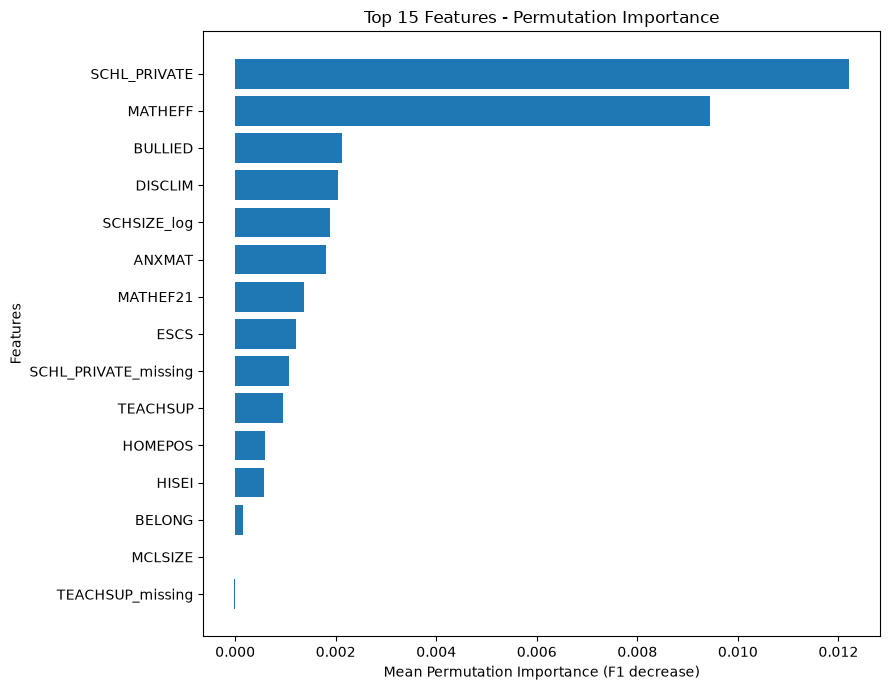

In [20]:
# Select the top 15 features
top_features = mean_importance.head(15).sort_values()

plt.figure(figsize=(9, 7))

plt.barh(
    top_features.index,
    top_features.values
)

plt.xlabel('Mean Permutation Importance (F1 decrease)')
plt.ylabel('Features')
plt.title('Top 15 Features - Permutation Importance')

plt.tight_layout()
plt.show()

In [ ]:
## Nested Cross-Validation Confusion Matrix Visualisation

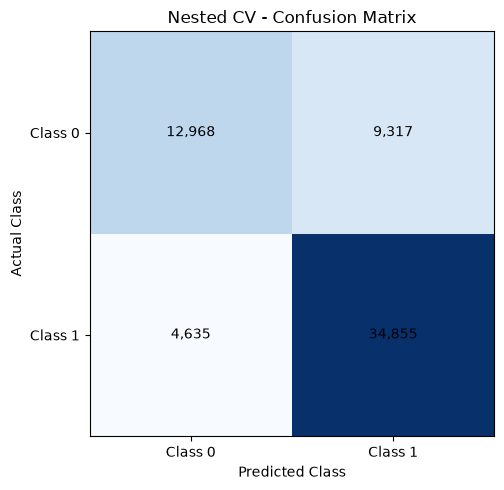

In [21]:
plt.figure(figsize=(7, 5))

plt.imshow(cm, cmap='Blues')

plt.title('Nested CV - Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.xticks([0, 1], ['Class 0', 'Class 1'])
plt.yticks([0, 1], ['Class 0', 'Class 1'])

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, f'{cm[i, j]:,}',
            ha='center',
            va='center'
        )

plt.tight_layout()
plt.show()

In [ ]:
## Random Forest Model Performance Comparison
#The original Random Forest, balanced Random Forest and nested cross-validation Random Forest configurations are compared using their evaluation metrics.

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,Balanced Accuracy
0,Original RF,0.7719,0.7908,0.8745,0.8305,0.7322
1,Balanced RF,0.7677,0.8161,0.8219,0.8189,0.7468
2,Nested CV RF,0.7741,0.7891,0.8826,0.8332,0.7323


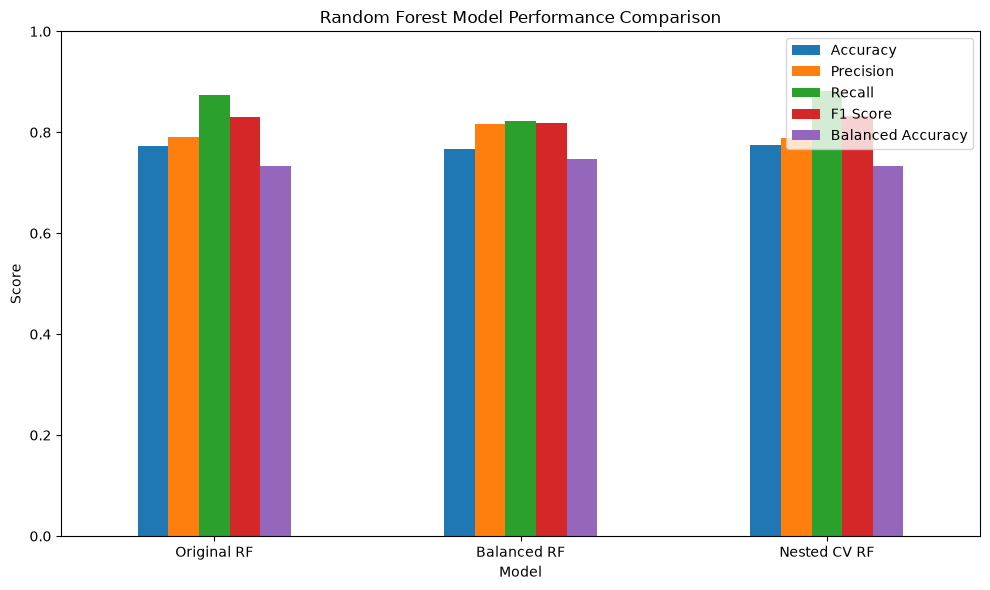

In [22]:
comparison = pd.DataFrame({
    'Model': ['Original RF', 'Balanced RF', 'Nested CV RF'],
    'Accuracy': [0.7719, 0.7677, 0.7741],
    'Precision': [0.7908, 0.8161, 0.7891],
    'Recall': [0.8745, 0.8219, 0.8826],
    'F1 Score': [0.8305, 0.8189, 0.8332],
    'Balanced Accuracy': [0.7322, 0.7468, 0.7323]
})

print("MODEL PERFORMANCE COMPARISON")
display(comparison.round(4))

comparison.set_index('Model').plot(
    kind='bar',
    figsize=(10, 6),
    ylim=(0, 1)
)

plt.title('Random Forest Model Performance Comparison')
plt.ylabel('Score')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()